In [63]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from sklearn.ensemble import RandomForestRegressor
from sklearn.decomposition import PCA
import joblib
import warnings

from deseasonalizer import ClimatologyDeseasonalizer

warnings.filterwarnings("ignore", category=RuntimeWarning)

In [64]:
PATH = r"E:\satdata\Custom\yucatan_sst_chlor_cdomslope_ssl_bathy_2010-2019_v3.pkl"
MODEL_PATH = r"F:\Programming\GitHub\nasa-murep\yucatan\experiments\isolation_forest\iforest_pipeline2.joblib"

features = ["chlor", "ssl_anom", "sst_anom"]

In [65]:
# with open(PATH, "rb") as f:
#     blob = pickle.load(f)

# df = blob["data"]
# metadata = blob["metadata"]
# df = df[(df.index.year >= 2010) & (df.index.year <= 2019)]

# grid_shape = np.asarray(df["sst"].iloc[0]).shape

# def shape_ok(a):
#     return a is not None and np.asarray(a).shape == grid_shape

# keep = df["sst"].apply(shape_ok) & df["chlorophyll"].apply(shape_ok) & df["ssl"].apply(shape_ok)
# df = df[keep]

# sst_stack = np.stack(df["sst"].to_numpy()).astype(float)
# chlor_stack = np.stack(df["chlorophyll"].to_numpy()).astype(float)
# ssl_stack = np.stack(df["ssl"].to_numpy()).astype(float)

# print(f"Loaded {len(df):,} days, grid shape {grid_shape}")

In [66]:
bundle = joblib.load(MODEL_PATH)
deseasonalizer = bundle["deseasonalizer"]
iforest_pipeline = bundle["iforest_pipeline"]
features = bundle.get("features", features)

preprocess = iforest_pipeline.named_steps["preprocess"]
iforest = iforest_pipeline.named_steps["iforest"]
print(f"Loaded pipeline bundle from {MODEL_PATH}")
print(f"Features: {features}")

Loaded pipeline bundle from F:\Programming\GitHub\nasa-murep\yucatan\experiments\isolation_forest\iforest_pipeline2.joblib
Features: ['chlor', 'ssl_anom', 'sst_anom']


In [67]:
def analyze_window(start_date, end_date, percentile=95):
    window_mask = (df.index >= start_date) & (df.index <= end_date)
    n_days = int(window_mask.sum())
    if n_days == 0:
        raise ValueError(f"No valid days found between {start_date.date()} and {end_date.date()}")

    with np.errstate(invalid="ignore"):
        mean_sst = np.nanmean(sst_stack[window_mask], axis=0)
        mean_chlor = np.nanmean(chlor_stack[window_mask], axis=0)
        mean_ssl = np.nanmean(ssl_stack[window_mask], axis=0)

    window_doys = np.clip(df.index[window_mask].dayofyear.to_numpy(), None, 365) - 1
    sst_clim = np.nanmean(deseasonalizer.climatology_["sst"][:, :, window_doys], axis=-1)
    ssl_clim = np.nanmean(deseasonalizer.climatology_["ssl"][:, :, window_doys], axis=-1)

    sst_anom_map = mean_sst - sst_clim
    ssl_anom_map = mean_ssl - ssl_clim

    valid_2d = (
        ~np.isnan(mean_sst) & ~np.isnan(mean_chlor) & ~np.isnan(mean_ssl)
        & (mean_chlor > 0)
        & ~np.isnan(sst_anom_map) & ~np.isnan(ssl_anom_map)
    )
    row_w, col_w = np.where(valid_2d)

    X_window = pd.DataFrame({
        "chlor": mean_chlor[valid_2d],
        "ssl_anom": ssl_anom_map[valid_2d],
        "sst_anom": sst_anom_map[valid_2d],
    })[features]

    X_window_transformed = preprocess.transform(X_window)

    anomaly_score = -iforest.decision_function(X_window_transformed)
    raw_anomaly = anomaly_score >= np.percentile(anomaly_score, percentile)

    sst_anom_z = X_window_transformed["normal__sst_anom"].to_numpy()
    ssl_anom_z = X_window_transformed["skewed__ssl_anom"].to_numpy()

    is_upwelling = raw_anomaly & (sst_anom_z < 0) & (ssl_anom_z < 0)

    return {
        "start_date": start_date,
        "end_date": end_date,
        "n_days": n_days,
        "X_window": X_window,
        "X_window_transformed": X_window_transformed,
        "anomaly_score": anomaly_score,
        "is_upwelling": is_upwelling,
        "non_upwelling": ~is_upwelling,
        "row_w": row_w,
        "col_w": col_w,
        "valid_2d": valid_2d,
    }

In [68]:
result = analyze_window(pd.Timestamp("2018-06-01"), pd.Timestamp("2018-06-30"), 80)

In [69]:
# # RF surrogate, predict IF anomaly score from transformed features
# surrogate = RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42, n_jobs=-1)
# surrogate.fit(result["X_window_transformed"], result["anomaly_score"])

# importances = surrogate.feature_importances_
# feature_names = result["X_window_transformed"].columns
# importance_dict = {name: weight * 100 for name, weight in zip(feature_names, importances)}

# print("\n--- Feature Importance (% of variance in anomaly score explained) ---")
# for feat, imp in sorted(importance_dict.items(), key=lambda item: item[1], reverse=True):
#     print(f"{feat:>18}: {imp:>5.1f}%")

In [70]:
X_window = result["X_window"]
is_upwelling = result["is_upwelling"]
non_upwelling_mask = result["non_upwelling"]

print(f"\n--- Window: {result['start_date'].date()} to {result['end_date'].date()} ({result['n_days']} days averaged) ---")
print(f"Total Valid Pixels: {len(X_window):,}")
print(f"Upwelling Anomalies: {is_upwelling.sum():,}\n")

print("Mean States (Upwelling Anomaly vs Non-Anomaly):")
print(f"SST anom | Upwelling: {X_window['sst_anom'][is_upwelling].mean():.3f} \u00b0C | Non-Anomaly: {X_window['sst_anom'][non_upwelling_mask].mean():.3f} \u00b0C")
print(f"Chlor    | Upwelling: {X_window['chlor'][is_upwelling].mean():.3f} mg/m3 | Non-Anomaly: {X_window['chlor'][non_upwelling_mask].mean():.3f} mg/m3")
print(f"SSL anom | Upwelling: {X_window['ssl_anom'][is_upwelling].mean():.3f} m | Non-Anomaly: {X_window['ssl_anom'][non_upwelling_mask].mean():.3f} m\n")


--- Window: 2018-06-01 to 2018-06-30 (30 days averaged) ---
Total Valid Pixels: 44,744
Upwelling Anomalies: 6,014

Mean States (Upwelling Anomaly vs Non-Anomaly):
SST anom | Upwelling: -0.699 °C | Non-Anomaly: -0.286 °C
Chlor    | Upwelling: 2.189 mg/m3 | Non-Anomaly: 0.279 mg/m3
SSL anom | Upwelling: -0.028 m | Non-Anomaly: -0.005 m



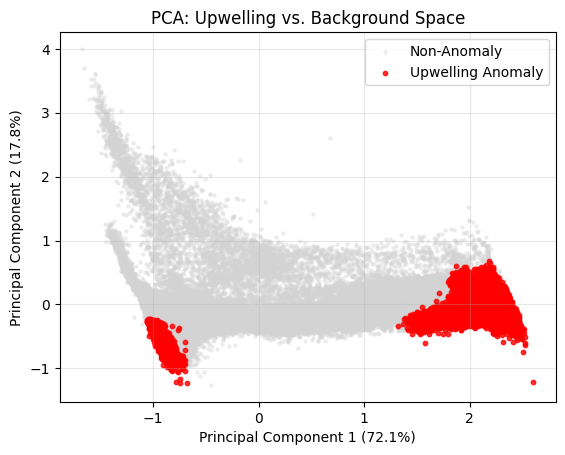

In [71]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(result["X_window_transformed"])
var_explained = pca.explained_variance_ratio_ * 100

plt.scatter(X_pca[non_upwelling_mask, 0], X_pca[non_upwelling_mask, 1],
            c='lightgray', alpha=0.3, s=5, label='Non-Anomaly')
plt.scatter(X_pca[is_upwelling, 0], X_pca[is_upwelling, 1],
            c='red', alpha=0.8, s=10, label='Upwelling Anomaly')
plt.title("PCA: Upwelling vs. Background Space")
plt.xlabel(f"Principal Component 1 ({var_explained[0]:.1f}%)")
plt.ylabel(f"Principal Component 2 ({var_explained[1]:.1f}%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

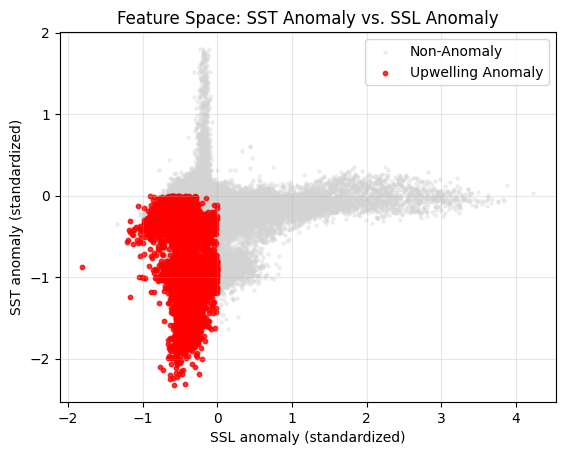

In [72]:
nu_ssl = result["X_window_transformed"]["skewed__ssl_anom"][non_upwelling_mask]
u_ssl  = result["X_window_transformed"]["skewed__ssl_anom"][is_upwelling]
nu_sst = result["X_window_transformed"]["normal__sst_anom"][non_upwelling_mask]
u_sst  = result["X_window_transformed"]["normal__sst_anom"][is_upwelling]

plt.scatter(nu_ssl, nu_sst,
            c='lightgray', alpha=0.3, s=5, label='Non-Anomaly')
plt.scatter(u_ssl, u_sst,
            c='red', alpha=0.8, s=10, label='Upwelling Anomaly')
plt.title("Feature Space: SST Anomaly vs. SSL Anomaly")
plt.xlabel("SSL anomaly (standardized)")
plt.ylabel("SST anomaly (standardized)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

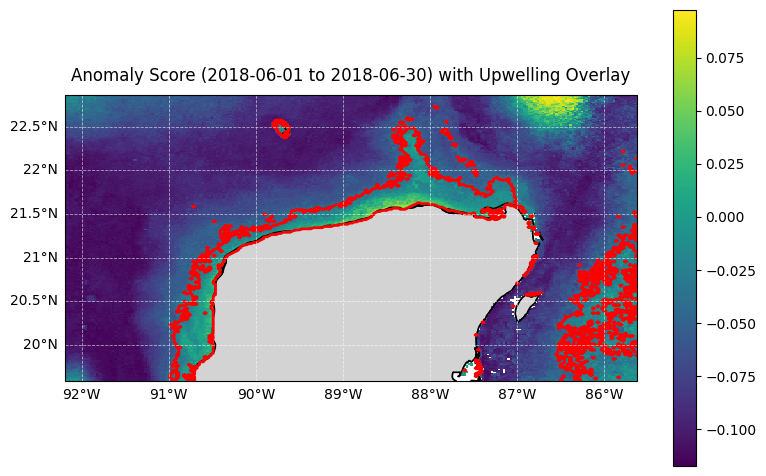

In [73]:
score_map = np.full(grid_shape, np.nan)
score_map[result["row_w"], result["col_w"]] = result["anomaly_score"]

binary_mask = np.zeros(grid_shape, dtype=float)
binary_mask[result["row_w"][is_upwelling], result["col_w"][is_upwelling]] = 1.0

lon_centers = np.array(metadata["lon_centers"])
lat_centers = np.array(metadata["lat_centers"])
lon_grid_2d, lat_grid_2d = np.meshgrid(lon_centers, lat_centers)

fig, ax = plt.subplots(
    figsize=(8, 6), subplot_kw={"projection": ccrs.PlateCarree()}
)

ax.set_extent(
    [lon_centers.min(), lon_centers.max(), lat_centers.min(), lat_centers.max()],
    crs=ccrs.PlateCarree(),
)

mesh = ax.pcolormesh(
    lon_grid_2d, lat_grid_2d, score_map,
    cmap="viridis", transform=ccrs.PlateCarree(), shading="auto"
)

ax.contour(
    lon_grid_2d, lat_grid_2d, binary_mask,
    levels=[0.5], colors="red", linewidths=2.0, transform=ccrs.PlateCarree()
)

ax.add_feature(cfeature.LAND, facecolor="lightgray", edgecolor="black", linewidth=0.8)
ax.add_feature(cfeature.COASTLINE, linewidth=1.2)
gl = ax.gridlines(draw_labels=True, linewidth=0.6, color="white", alpha=0.6, linestyle="--")
gl.top_labels = False
gl.right_labels = False

ax.set_title(f"Anomaly Score ({result['start_date'].date()} to {result['end_date'].date()}) with Upwelling Overlay", pad=10)
fig.colorbar(mesh, ax=ax, orientation="vertical", shrink=0.8, pad=0.05)

plt.tight_layout()
plt.show()